## Plot the time evolution of each model as a 2-D slice for each field parameter

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data
from field_config import field_cmaps, field_lims, shck_color_list, shck_tick_num, shck_ticks, field_scales

import flash_amr_tools
import h5py

In [35]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

In [36]:
sims = ["ISM-v30", "ISM-v30-MDiff", "ISM-v30-HDiff", "ISM-v100"]
times = [30, 60, 90, 120]
field = "encr"

sim_textlabel = {
    "ISM-v30" : (11, -22),
    "ISM-v30-MDiff" : (11, -22),
    "ISM-v30-HDiff" : (11, -22),
    "ISM-v100" : (8, -22),
    "ISM-v30-MHD" : (11, -22),
}

field_labels = {
    "dens" : r"Density $\rho$ / g cm$^{-3}$",
    "pres" : r"Pressure $P$ / K cm$^{-3}$",
    "mag" : r"Magnetic Field Strength $|\vec{B}|^2$ / G",
    "encr" : r"CR Energy Density $\epsilon_\mathrm{CR}$ / erg cm$^{-3}$",
}

In [37]:
def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

Processing time 30 kyr
Processing simulation ISM-v30
/home/kwatanabe/Projects/cr-bowshocks/outputs_new/ISM_v30_CR/starISM_hdf5_plt_cnt_0005
minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
13533 13533
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 15320
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given 

bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 27104
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
Processing simulation ISM-v30-MDiff
/home/kwatanabe/Projects/cr-bowshocks/outputs_new/ISM_v30_CR_MDiff/starISM_hdf5_plt_cnt_0006
minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
22185 22185
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefi

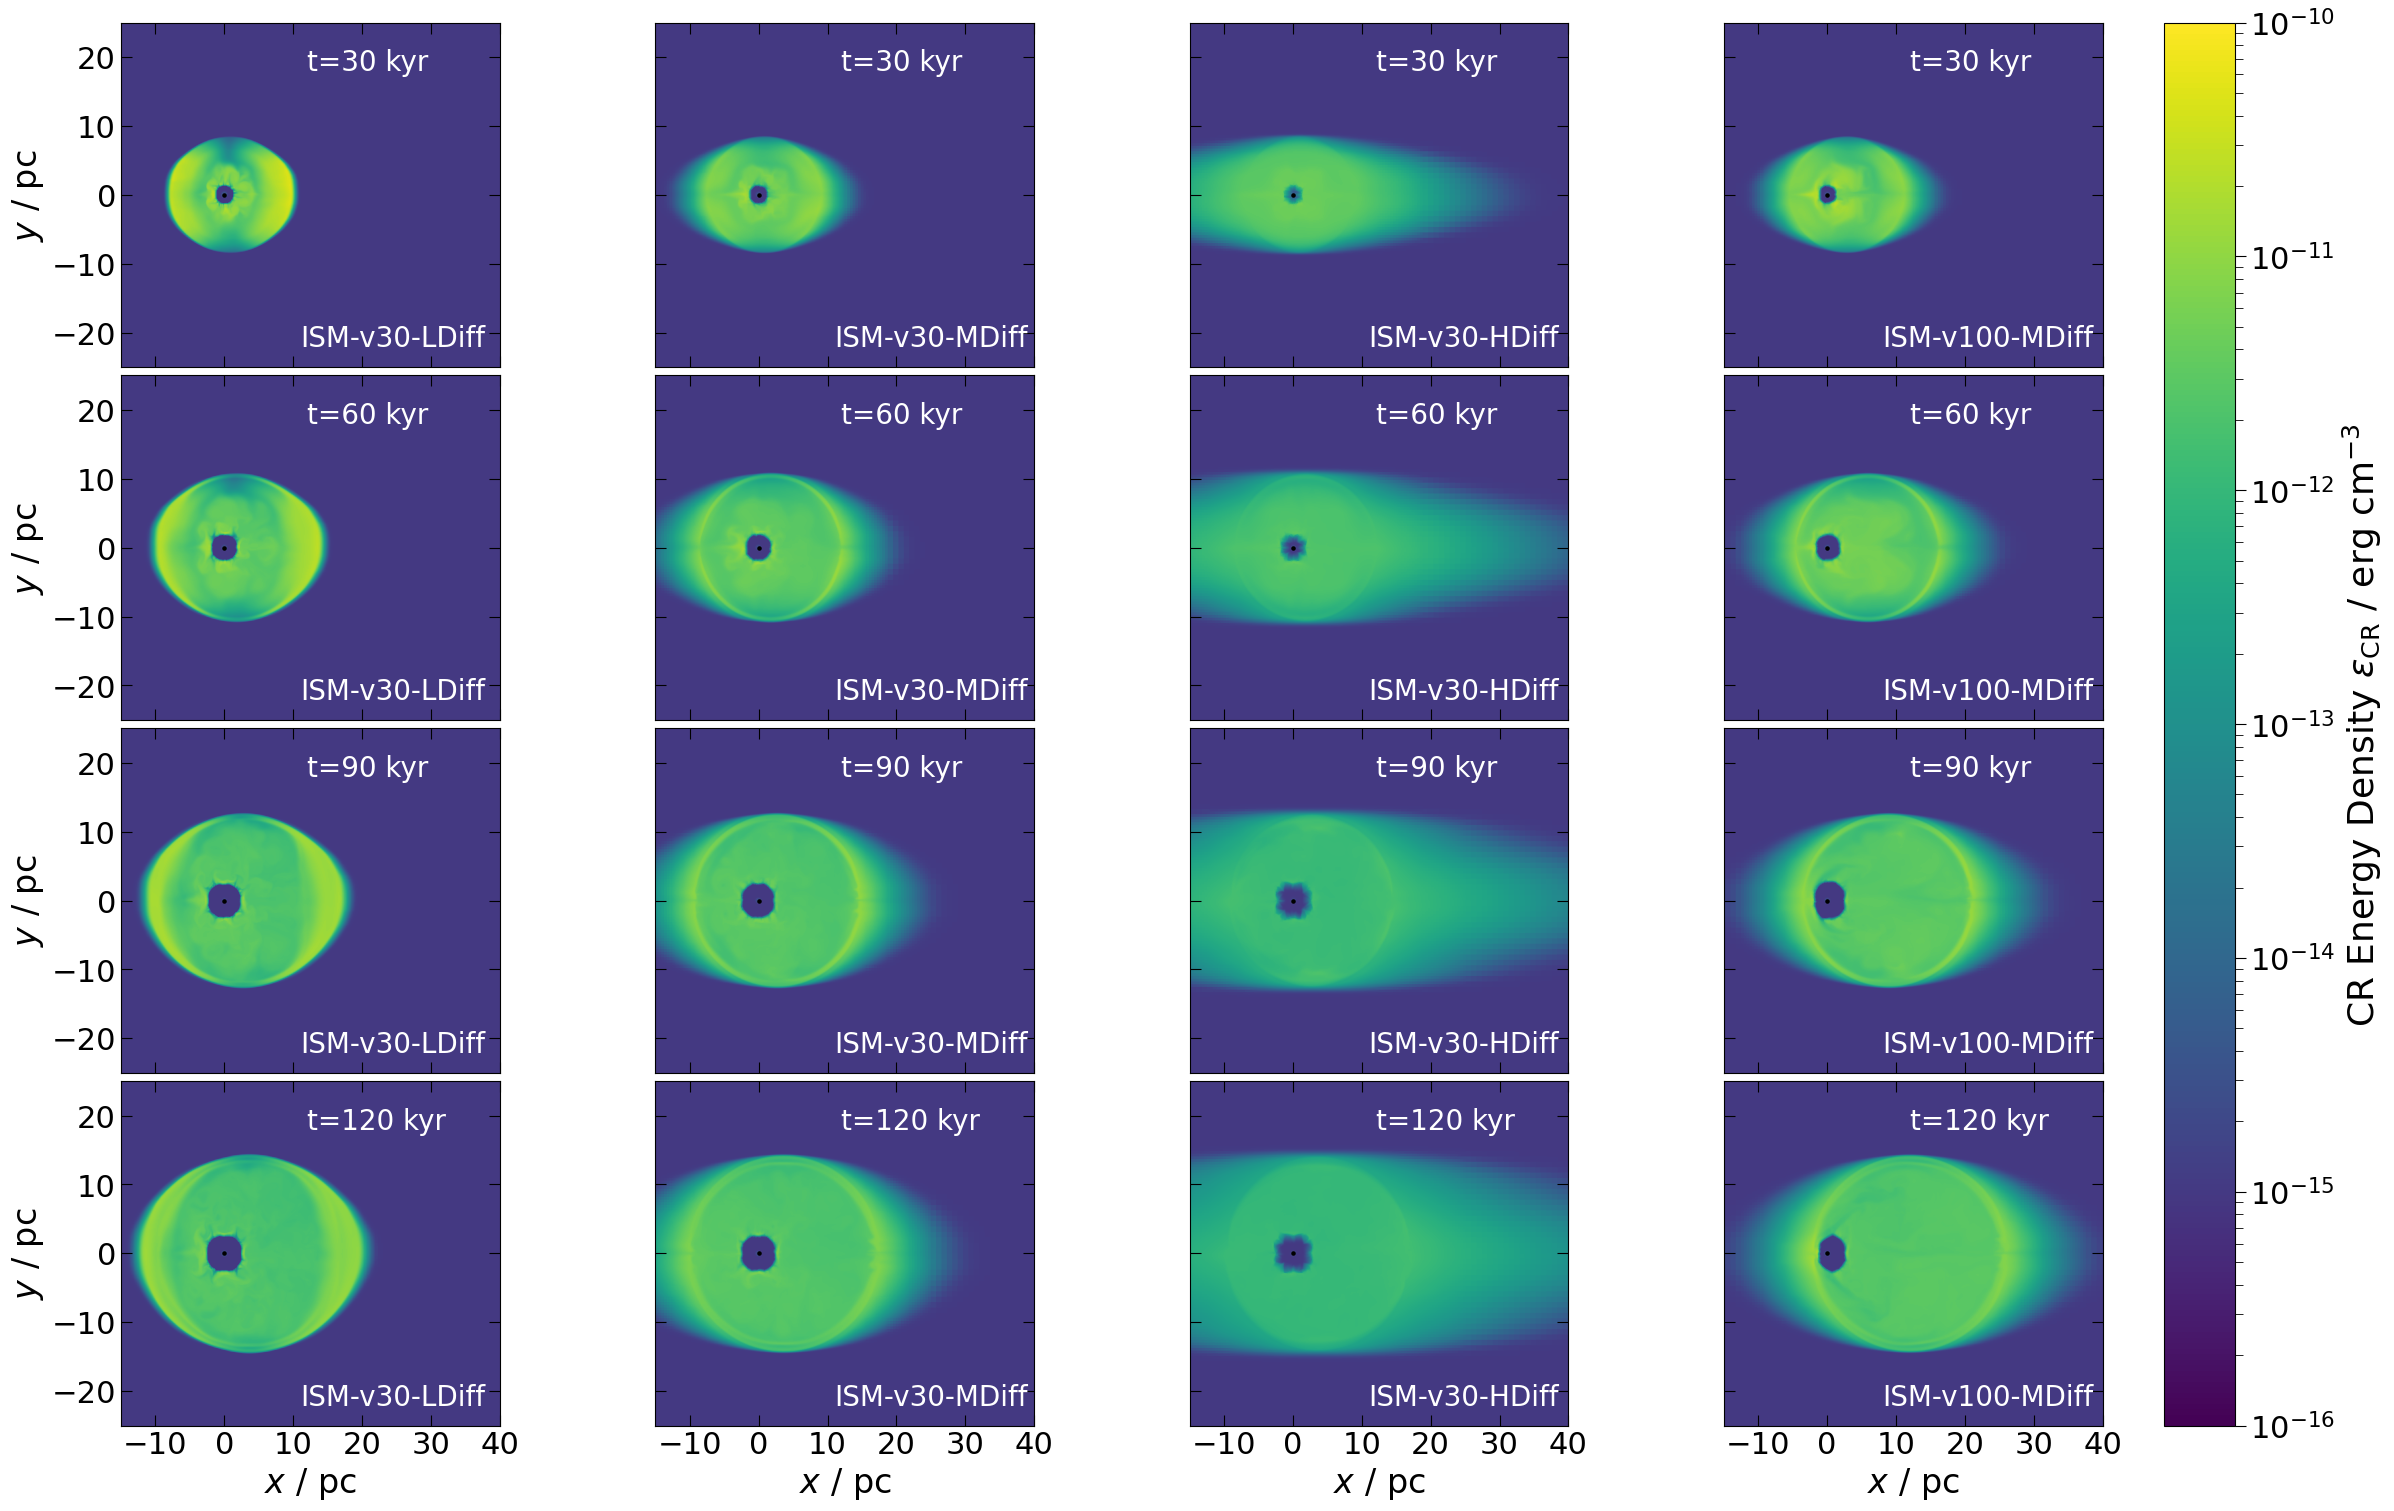

In [38]:
fig = plt.figure(figsize=(24,15), constrained_layout=True)
gs = fig.add_gridspec(len(times), len(sims), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=True)

for itime, time in enumerate(times):
    print(f"Processing time {time} kyr")
    for isim, sim in enumerate(sims):
        print(f"Processing simulation {sim}")
        sim_dir = os.path.join(flash_output_dir, bowshock_config[sim]["sim_dir"])

        # do an iterative search for the simulation file
        sim_file = find_hdf5_file_from_time(time, sim_dir)
        print(sim_file)
        # sim_file = os.path.join(sim_dir, f"starISM_hdf5_plt_cnt_{time//10:04d}")
        
        blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

        pf = h5py.File(sim_file)
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

        # extent for imshow
        extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

        field_data = get_transformed_data(pf, field, blist)
        field_slice = flash_amr_tools.get_slice(field_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

        # normaliztion for color
        if field == "shck":
            # define bins and normalize
            bounds = np.array([1, 3, 5, 7]) - 1
            norm = mcolors.BoundaryNorm(bounds, len(shck_color_list))
        elif field in ("shma", "mach", "crac", "mgob"):
            norm = mcolors.Normalize(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)
        else:
            norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

        im = axs[itime, isim].imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent)
        axs[itime, isim].scatter(0, 0, s=5.0, color="k")

        # limits
        axs[itime, isim].set_xlim(-15,40)
        axs[itime, isim].set_ylim(-25,25)

        # add annotations for the simulation labels
        textcolor = "w" if field == "encr" else "k"
        axs[itime, isim].annotate(f"t={time} kyr", xy=(12, 18), color=textcolor, fontsize=20, zorder=100)
        axs[itime, isim].annotate(bowshock_config[sim]["label"], xy=sim_textlabel[sim], color=textcolor, fontsize=20, zorder=100)

        # labels
        if itime == len(times) -1:
            axs[itime, isim].set_xlabel("$x$ / pc", fontsize=24)
        if isim == 0 :
            axs[itime, isim].set_ylabel("$y$ / pc", fontsize=24)

        if itime == len(times) -1:
            # ticks
            axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=22, top=True, right=True)
            axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=20, top=True, right=True)
        else:
            axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=0, top=True, right=True)
            axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=0, top=True, right=True)
        if isim == 0:
            axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=22, top=True, right=True)
            axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=20, top=True, right=True)
        else:
            # ticks
            axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=0, top=True, right=True)
            axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=0, top=True, right=True)

        # if isim == len(sims)-1:
        #     # colorbar
        #     # make separate axes for each image
        #     # divider = make_axes_locatable(axs[itime, isim])
        #     # cax = divider.append_axes("bottom", size="5%", pad=0.1)
        #     sm = cm.ScalarMappable(cmap=field_cmaps[field], norm=norm)

        #     # set ticks as text for shck
        #     if field == "shck":
        #         cb = fig.colorbar(sm, ax=axs[itime, isim], ticks=shck_tick_num, orientation="vertical")
        #         cb.ax.set_yticklabels(shck_ticks, rotation=90)
        #         cb.ax.tick_params(axis='both', which='major', size=0, labelsize=14.5)
        #         cb.ax.tick_params(axis='both', which='minor', size=0)

        #     else:
        #         cb = fig.colorbar(sm, ax=axs[itime, isim], orientation="vertical")
        #         cb.ax.set_ylabel(field_labels[field], fontsize=22)
        #         cb.ax.tick_params(axis='both', which='major', size=8, labelsize=22)
        #         cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=22)

        #         # scales
        #         cb.ax.set_yscale(field_scales[field])
        #     # cb.ax.tick_params(rotation=90)

        pf.close()
cb = fig.colorbar(im, ax=axs.ravel().tolist(), orientation="vertical", pad=0.02)
cb.ax.set_ylabel(field_labels[field], fontsize=26)
cb.ax.tick_params(axis='both', which='major', size=8, labelsize=22)
cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=22)
cb.ax.set_yscale(field_scales[field])

fig.savefig(f"{fig_dir}/2d_slices_{field}_timeevo.png", dpi=250, bbox_inches="tight")